<a href="https://colab.research.google.com/github/bfs0/SDAIA_Athkax_A-B_Testing_PROJECT/blob/main/Copy_of_%D8%AA%D9%85%D8%B1%D9%8A%D9%86_3_3%D8%8C_%D8%A7%D9%84%D9%81%D8%B1%D9%88%D9%82_%D9%81%D9%8A_%D8%A7%D9%84%D9%81%D8%B1%D9%88%D9%82_%D9%88%D8%A7%D8%AE%D8%AA%D8%A8%D8%A7%D8%B1_%D9%88%D9%87%D9%85%D9%8A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# تمرين 3.3: الفروق في الفروق واختبار وهمي

**برنامج التجارب واختبارات A/B والاستدلال السببي**، اليوم الثالث

**الخطوات:**
1. من قائمة File اختر Save a copy in Drive، واعمل على النسخة التي تُفتح.
2. شغّل الخلايا بالترتيب، ثم اكتب حلك في الخلية المخصصة.
3. اضغط Share، واجعل General access على Anyone with the link بصلاحية Viewer، ثم اضغط Copy link.
4. الصق الرابط في ملف التقييم الخاص بمجموعتك، في عمود «تمرين 3.3».

</div>

<div dir="rtl">

## الإعداد

شغّل الخلية التالية أولًا.

</div>

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import html
from IPython.display import HTML, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import ft2font
from scipy import stats

# الإصدارات الحديثة من matplotlib تعرض العربية مباشرة، والقديمة تحتاج مكتبتين صغيرتين
NATIVE_ARABIC = hasattr(ft2font, "__libraqm_version__")
if not NATIVE_ARABIC:
    try:
        import arabic_reshaper
        from bidi.algorithm import get_display
    except ImportError:
        import subprocess
        import sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "arabic-reshaper", "python-bidi"], check=True)
        import arabic_reshaper
        from bidi.algorithm import get_display

rng = np.random.default_rng(2026)

# ألوان البرنامج: A تركوازي، وB برتقالي، والقيمة الحقيقية كحلي، والطريقة الساذجة رمادي
TEAL, ORANGE, NAVY, GRAY = "#0E7490", "#E58A1F", "#0F2A3F", "#A9B4BC"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.prop_cycle": cycler(color=[TEAL, ORANGE, NAVY, GRAY]),
    "axes.edgecolor": "#56656F", "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": "#3D4F5C", "ytick.color": "#3D4F5C",
    "axes.grid": True, "grid.color": "#D8E1E7", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.precision", 4)


def ar(text):
    """يجهز النص العربي ليظهر بالشكل والاتجاه الصحيحين داخل الرسوم."""
    text = str(text)
    return text if NATIVE_ARABIC else get_display(arabic_reshaper.reshape(text))


def say(*parts, sep=" "):
    """يطبع نصًا عربيًا من اليمين إلى اليسار."""
    text = html.escape(sep.join(str(p) for p in parts))
    display(HTML(f'<div dir="rtl" style="white-space: pre-wrap; line-height: 1.7;">{text}</div>'))

import statsmodels.formula.api as smf
from sklearn.neighbors import NearestNeighbors


def tidy(fit, terms=None):
    """جدول مختصر لنتيجة الانحدار."""
    ci = fit.conf_int()
    out = pd.DataFrame({"المعامل": fit.params, "SE": fit.bse, "أدنى 95%": ci[0], "أعلى 95%": ci[1], "p": fit.pvalues})
    return out.loc[terms] if terms else out


def smd(x, group):
    """الفرق المعياري بين متوسطي مجموعتين."""
    x, group = np.asarray(x, dtype=float), np.asarray(group)
    a, b = x[group == 1], x[group == 0]
    return (a.mean() - b.mean()) / np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)


say("الإعداد جاهز")

<div dir="rtl">

## الأدوات الجاهزة

هذه الدوال والبيانات من دفتر اليوم، ويحتاجها التمرين. شغّلها كما هي.

</div>

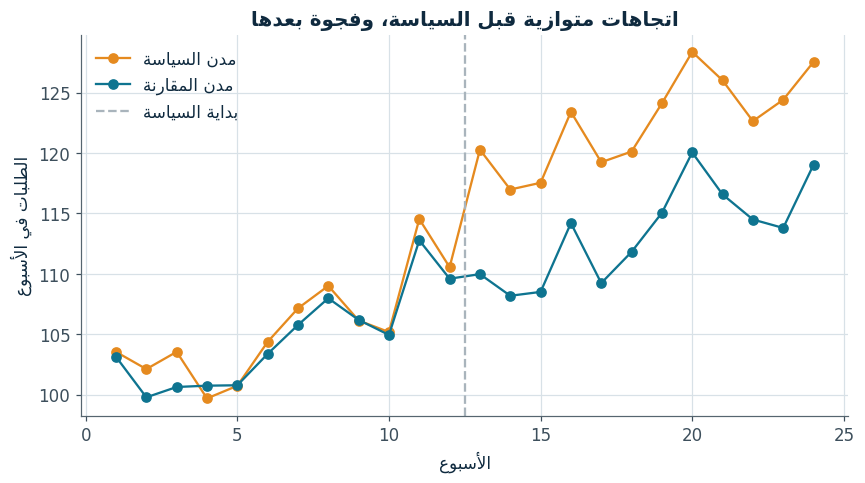

In [ ]:
def simulate_cities(n_cities=20, n_weeks=24, policy_week=13, effect=8.0, treated_trend_extra=0.0, seed=32):
    r = np.random.default_rng(seed)
    city_level = r.normal(100, 15, n_cities)
    week_shock = r.normal(0, 2, n_weeks)
    rows = []
    for i in range(n_cities):
        is_treated = i < 6
        for w in range(1, n_weeks + 1):
            y = (city_level[i] + 0.8 * w + week_shock[w - 1]
                 + (treated_trend_extra * w if is_treated else 0)
                 + (effect if (is_treated and w >= policy_week) else 0)
                 + r.normal(0, 3))
            rows.append({"city": f"city_{i:02d}", "week": w, "treated": int(is_treated),
                         "post": int(w >= policy_week), "orders": y})
    df = pd.DataFrame(rows)
    df["treated_post"] = df["treated"] * df["post"]
    df["city_id"] = pd.factorize(df["city"])[0]
    return df


panel = simulate_cities()
trend = panel.groupby(["week", "treated"])["orders"].mean().unstack()
plt.plot(trend.index, trend[1], marker="o", color=ORANGE, label=ar("مدن السياسة"))
plt.plot(trend.index, trend[0], marker="o", color=TEAL, label=ar("مدن المقارنة"))
plt.axvline(12.5, color=GRAY, linestyle="--", label=ar("بداية السياسة"))
plt.xlabel(ar("الأسبوع"))
plt.ylabel(ar("الطلبات في الأسبوع"))
plt.title(ar("اتجاهات متوازية قبل السياسة، وفجوة بعدها"))
plt.legend()
plt.show()

<div dir="rtl">

## المطلوب

1. **بالحساب اليدوي:** زادت الطلبات اليومية في الرياض من 100 إلى 120 بعد سياسة جديدة، وزادت في جدة (بدون السياسة) من 80 إلى 90. كم أثر السياسة؟
2. **اختبار وهمي (Placebo):** خذ بيانات `panel` **قبل** الأسبوع 13 فقط، وافترض أن السياسة بدأت في الأسبوع 7. قدّر أثر الفروق في الفروق. ما النتيجة التي يجب أن تظهر؟

</div>

In [ ]:
# 2) pre = panel[panel.week < 13].copy() ثم أنشئ العمودين fake_post و fake_treated_post
a = (120 - 100) - (90 - 80)
print("اثر السياسة : ", a) # 1. احسب اثر السياسة
pre = panel[panel.week < 13].copy()
# نفترض أن السياسة بدأت في الأسبوع 7 (هذه سياسة وهمية، ما صار شيء حقيقي)
pre["fake_post"] = (pre["week"] >= 7).astype(int)

# نضرب المدينة المعالجة × فترة "ما بعد" الوهمية (نفس فكرة treated_post)
pre["fake_treated_post"] = pre["treated"] * pre["fake_post"]

# متوسط الطلبات لكل مجموعة (مدن السياسة / المقارنة) وكل فترة (قبل / بعد الوهمية)
g = pre.groupby(["treated", "fake_post"])["orders"].mean().unstack()
print(g.round(2))

# الفرق في الفروق على التقسيم الوهمي:
# (المعالجة بعد − المعالجة قبل) − (المقارنة بعد − المقارنة قبل)
placebo = (g.loc[1, 1] - g.loc[1, 0]) - (g.loc[0, 1] - g.loc[0, 0])
print("الأثر الوهمي: ", placebo.round(2)) # - 0.04


اثر السياسة :  10
fake_post       0       1
treated                  
0          101.43  107.89
1          102.35  108.77
الأثر الوهمي:  -0.04


<div dir="rtl">

## التسليم

انتهيت؟ اضغط Share، ثم Copy link، والصق الرابط في ملف التقييم في عمود «تمرين 3.3».

</div>